The fourth lattice example featuring more complicated fill, as well as how to apply specific transformations to certain cells in a repeating lattice. Unfortunately, universes do not have a `translation` attribute that can apply to its cells. This needs to be done when either creating regions, or defining the cell (if the fill is a universe).


In [1]:
%run -i clean_script.py
import openmc
import numpy as np

model = openmc.model.Model()
# Material definitions
materials=openmc.Materials()

m1 = openmc.Material()
m1.add_nuclide('Be9', 1)
m1.set_density('g/cc',0.6)
materials.append(m1)

m2 = openmc.Material()
m2.add_element('C',1.0)
m2.set_density('g/cc',0.8)
materials.append(m2)

m3 = openmc.Material()
m3.add_nuclide('Al27',1.0)
m3.set_density('g/cc',2.7)
materials.append(m3)

m4 = openmc.Material()
m4.add_nuclide('H1', 2)
m4.add_nuclide('O16', 1)
m4.set_density('g/cc',0.4)
materials.append(m4)
model.materials = materials

In [2]:
# Surface definitions
v = 15
s1 = openmc.XPlane(v,boundary_type='vacuum')
s2 = openmc.XPlane(-v,boundary_type='vacuum')
s3 = openmc.YPlane(v,boundary_type='vacuum')
s4 = openmc.YPlane(-v,boundary_type='vacuum')
s5 = openmc.Sphere(x0=7, y0 = 2.1, z0=0, r=3.5)
s6 = openmc.XPlane(4 ) #!!!!!!!
s7 = openmc.XPlane(-5) #!!!!!!
s8 = openmc.YPlane(2)
s9 = openmc.YPlane(-2)
s10 = openmc.Plane(0.7, -0.7, 0, -2.5) # apply negative to last
s11 = openmc.Plane(0.6, 0.8, 0, 0.5)
s12 = openmc.YPlane(-1)

# s13 is a quadric
import sympy as sp
p1 = (-4.5, 0, 0)
p2 = (-0.5, 1.7, 0)
p3 = (3.5, 0, 0)

x1,y1,z1 = map(sp.sympify,p1)
x2,y2,z2 = map(sp.sympify,p2)
x3,y3,z3 = map(sp.sympify,p3)
A,B,C,D,E,F,G,H,J,K = sp.symbols('A B C D E F G H J K')

eqs = []

# s13 is parallel to X
eqs += [
        sp.Eq(C,B),
        sp.Eq(D,0),
        sp.Eq(E,0),
        sp.Eq(F,0),
        sp.Eq(H,0),
        sp.Eq(J,0),
        sp.Eq(sp.sqrt(y2**2 + z2**2), -K)
    ]

def quadric_eq(x,y,z):
    return A*x **2 + B*y**2 + C*z**2 + D*x*y + E *y*z + F*x*z +G*x + H*y + J*z + K

q1 = quadric_eq(x1,y1,z1)
q2 = quadric_eq(x2,y2,z2)
q3 = quadric_eq(x3,y3,z3)
#print(q4)
eqs += [sp.Eq(equation, 0) for equation in [q1,q2,q3]]

unknowns = [A,B,C,D,E,F,G,H,J,K]

vals = sp.linsolve(eqs, unknowns)

# OpenMC does not appreciate being passed sympy objects, so need to convert to float.
quad_sol = next(iter(vals))
quad_sol_unp = [float(v.evalf()) for v in quad_sol]

for i in quad_sol_unp:
    print(i, type(i))
    
# unpack into surface definition
s13 = openmc.Quadric(*quad_sol_unp)

0.10793650793650793 <class 'float'>
0.5975723622782447 <class 'float'>
0.5975723622782447 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
0.10793650793650793 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
-1.7 <class 'float'>


In [3]:
s14 = openmc.XPlane(1.6)
s15 = openmc.XPlane(-1.4)
s16 = openmc.YPlane(1)
s17 = openmc.YPlane(-1.2)
s18 = openmc.XPlane(3)
s19 = openmc.XPlane(-3)
s20 = openmc.YPlane(0.5)
s21 = openmc.YPlane(-0.6)
s22 = openmc.ZPlane(6,boundary_type='vacuum')
s23 = openmc.ZPlane(-7,boundary_type='vacuum')
s24 = openmc.Sphere(r=10)

Take note of any cells with imp:n=0. In OpenMC, we will need to apply `boundary_type='vacuum'` to the surfaces of that cell.



<Axes: xlabel='x [cm]', ylabel='y [cm]'>

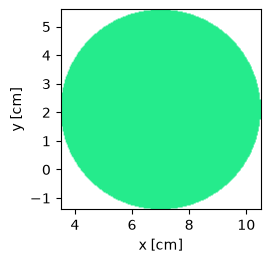

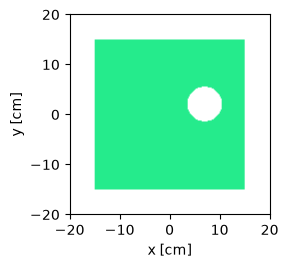

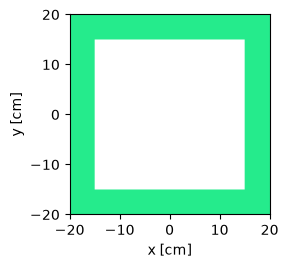

In [4]:
# Translation definitions
t1 = (0,0,0)
r1 = (0,0,10) # degrees
t2 = (1,0,0)
r2 = (0,0,2) # degrees
t3 = (3,0,0)

# Cell and Universe Definitions
c1 = openmc.Cell(fill=m1,region=-s5)
c1.plot()
c2 = openmc.Cell(fill=None,region=(-s1&+s2&-s3&+s4)&+s5&(-s22&+s23)) # To be filled with Universe 1 (c2 fill)
c2.plot(width=(40,40))
c3 = openmc.Cell(fill=None,region=+s1|-s2|+s3|-s4|+s22|-s23) # imp:n=0 
c3.plot(width=(40,40))

The difficulty with these MCNP lattice examples is:
1. Finding RectLattice parameters that will reproduce MCNP's automatic tessellation (if used)
2. Figuring out how a given MCNP lattice cell should be recreated using an OpenMC cell inside an OpenMC universe.

Remember that an `openmc.Cell` can be filled with either `openmc.Material`, `openmc.Universe`, or `openmc.Lattice`. 

Starting with the top-level Universe 1, the c4 region `-s6&+s7&-s8&+s9` forms a rectangular prism with dimensions x(-5 to 4), y(-2 to 2). Since the lattice goes as -2:2, -4:4, 0:0, the corresponding RectLattice parameters `lower_left` and `pitch` should be (-23, -18) and (9, 4) respectively.

There is one more very important subtlety to mention concerning `openmc.RectLattice`. 
According to its aforementioned parameters, RectLattice will generate a "lattice center point" for each of its universes. The universe is positioned such that its bounding box center will match the lattice center.

In normal use cases where the universe is symmetrically defined about its origin, this is fine, but since MCNP specifies `px -5` and `px 4` for `c4`, the element will be translated (-0.5, 0, 0) in its cell which will leave a +0.5 gap on the +x side of the element:

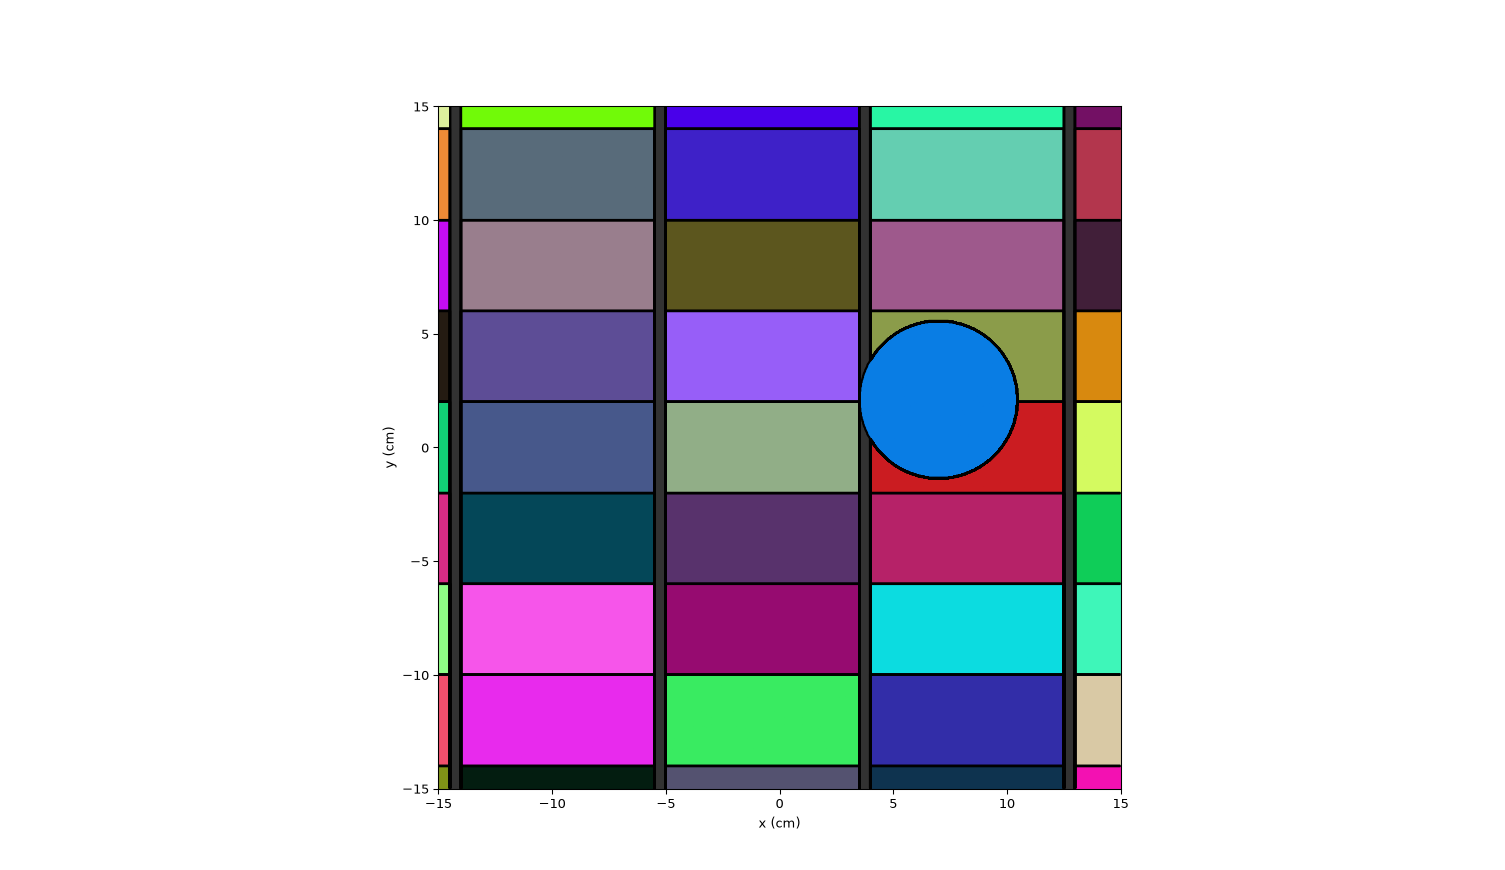
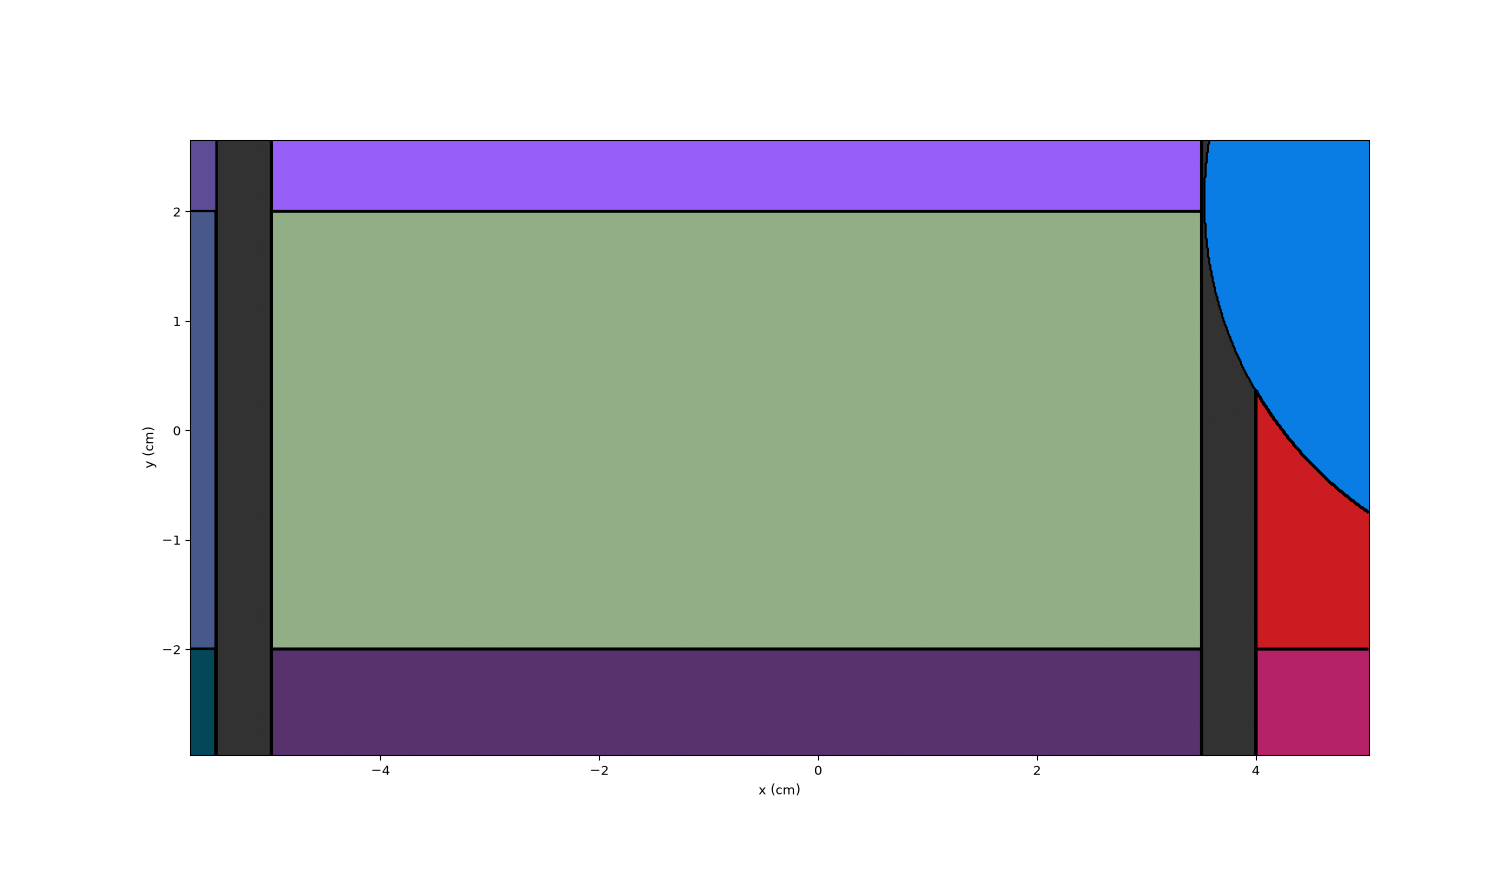

There are two ways to fix this:
1. Change s6 and s7 to x0=-4.5 and x0=4.5 respectively
2. Leave s6 and s7 unchanged, but translate c4's region to (+0.5, 0, 0).

Both will cause the bounding box of u1 to be `lower_left=(-4.5, -2,-inf)` and `upper_right=(4.5, 2, inf)` which is symmetric.

Shown below is option 2. We will have to do a similar thing for the other types of lattice elements yet to be defined.

BoundingBox(lower_left=(-5.0, -2.0, -inf), upper_right=(4.0, 2.0, inf))
BoundingBox(lower_left=(-4.5, -2.0, -inf), upper_right=(4.5, 2.0, inf))


<Axes: xlabel='x [cm]', ylabel='y [cm]'>

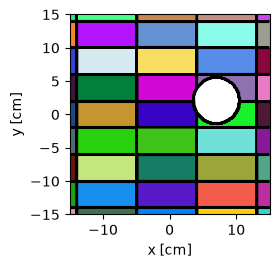

In [5]:
# Universe 1
#s6 = openmc.XPlane(4.5 ) #!!!!!!
#s7 = openmc.XPlane(-4.5) #!!!!!!
c4 = openmc.Cell(fill=m2,region=-s6&+s7&-s8&+s9) 
print(c4.bounding_box)
def u1():
    region = (-s6&+s7&-s8&+s9).translate((0.5,0,0))
    c4 = openmc.Cell(fill=m2,region= region)
    return openmc.Universe(cells=[c4])
print(u1().bounding_box)
c2_fill = openmc.RectLattice()
c2_fill.lower_left=(-23,-18)
c2_fill.pitch=(9,4)
c2_fill.outer=openmc.Universe(cells=[c3])
c2_fill.universes=[[u1(),u1(),u1(),u1(),u1()], 
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],]
c2.fill=c2_fill
c2.plot(outline=True)

In the MCNP definition, universes 2 and 4 sometimes have TR cards assigned to them in the lattice. Because we can only translate regions and/or fills, we should code our u2() and u4() functions to optionally accept these translations.

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

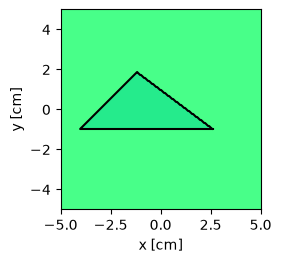

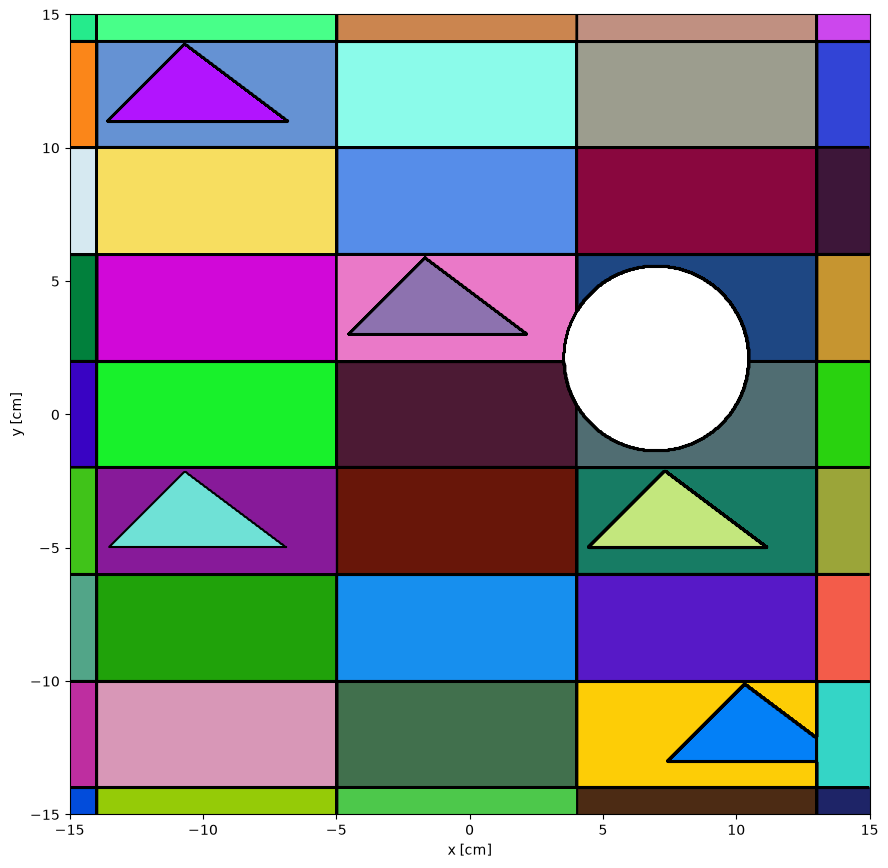

In [6]:
# Universe 2 (only has TR3 applied to it)
def u2(t=(0,0,0)):
    c5_region = (-s11&+s10&+s12).translate((0.5,0,0)) 
    # The above is our adjustment for the bbox issue discussed earlier. 
    # The next line is for the actual TR.
    c5_region = c5_region.translate(t)
    c6_region = ~c5_region
    c5 = openmc.Cell(fill=m3,region=c5_region)
    c6 = openmc.Cell(fill=m4,region=c6_region)
    return openmc.Universe(cells=[c5,c6])
geometry = openmc.Geometry(u2())
geometry.plot(outline=True)


# Note: in MCNP, filling goes from bottom row to top; left to right.
# In OpenMC, universe filling is written as one wants it to appear; 
c2_fill.universes=[[u1(),u1(),u1(),u1(),u1()], 
                   [u1(),u2(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u2(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u2(),u1(),u2(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u2(t3),u1()],
                   [u1(),u1(),u1(),u1(),u1()],]
c2.fill=c2_fill
c2.plot(pixels=(800,800),outline=True)

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

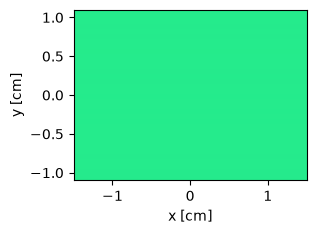

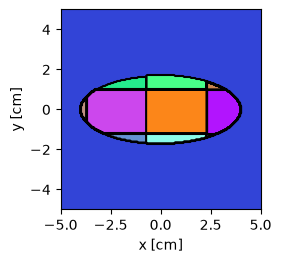

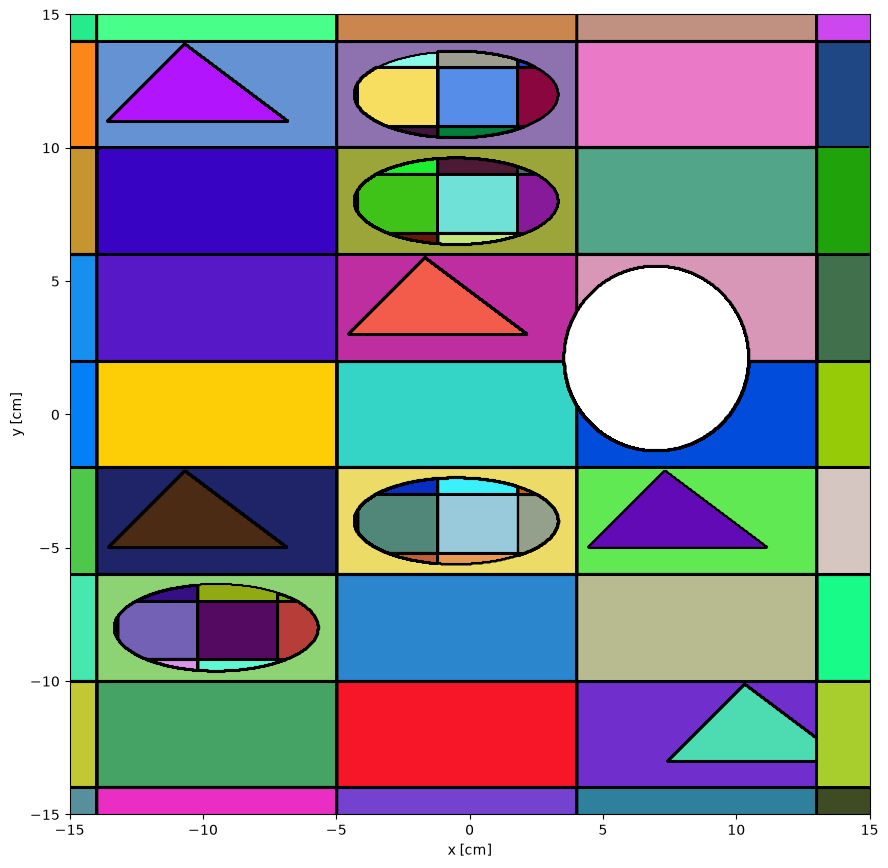

In [7]:
# Universe 3 (No translations, but lattice filled with u=5 required)

c10_list = [] # We can use this to set the f4 tally later. 
def u6():
    c10_region = -s24
    c10 = openmc.Cell(fill=m4,region=-s24)
    c10_list.append(c10)
    return openmc.Universe(cells=[c10])

def u5():
    # By inspection, we see that c9 has x(-1.4, 1.6), y(-1.2, 1), z(-3, 3).
    c9_region = (-s14&+s15&-s16&+s17).translate((-0.1, 0.1, 0))
    c9 = openmc.Cell(fill=u6(),region=c9_region)
    return openmc.Universe(cells=[c9])
geometry=openmc.Geometry(u5())
geometry.plot(outline=True)

def u3():
    # First, define the lattice.
    c7_fill = openmc.RectLattice()
    c7_fill.pitch=(3,2.2)
    c7_fill.lower_left=(-6.7,-3.4) #(-1.4-6,-1.2-2.2)
    c7_fill.universes=[[u5(),u5(),u5(),u5(),],
                       [u5(),u5(),u5(),u5(),],
                       [u5(),u5(),u5(),u5(),],]
    c7_region = (-s13).translate((0.5,0,0))
    c8_region = (+s13).translate((0.5,0,0))
    c8 = openmc.Cell(fill=m3,region=c8_region)
    c7 = openmc.Cell(fill=c7_fill,region=c7_region) # To be filled with a lattice u=5
    return openmc.Universe(cells=[c7,c8])

geometry = openmc.Geometry(u3())
geometry.plot(outline=True)

# Note: universe filling is written as it appears in OpenMC; 
# in MCNP, filling goes from bottom row to top; left to right.
c2_fill.universes=[[u1(),u1(),u1(),u1(),u1()], 
                   [u1(),u2(),u3(),u1(),u1()],
                   [u1(),u1(),u3(),u1(),u1()],
                   [u1(),u1(),u2(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u2(),u3(),u2(),u1()],
                   [u1(),u3(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u2(t3),u1()],
                   [u1(),u1(),u1(),u1(),u1()],]
c2.fill=c2_fill
c2.plot(pixels=(800,800),outline=True)



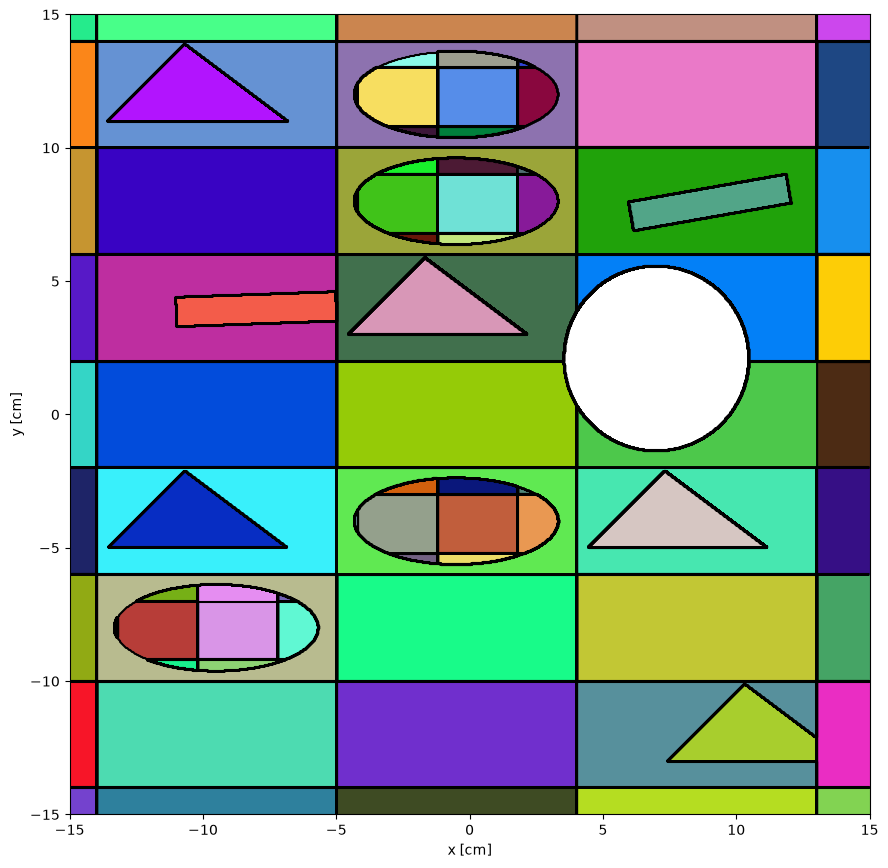

In [8]:
# Universe 4 (takes two different TR cards)
def u4(t=(0,0,0),r=(0,0,0)):
    c11_region = (-s18&+s19&-s20&+s21).rotate(r).translate(t).translate((0.5,0,0))
    c12_region = ~c11_region
    c11 = openmc.Cell(fill=m3,region=c11_region)
    c12 = openmc.Cell(fill=m4,region=c12_region)
    return openmc.Universe(cells=[c11,c12])


c10_list = [] # We'll reset this list.

c2_fill.universes=[[u1(),u1(),u1(),u1(),u1()], 
                   [u1(),u2(),u3(),u1(),u1()],
                   [u1(),u1(),u3(),u4(t1,r1),u1()],
                   [u1(),u4(t2,r2),u2(),u1(),u1()],
                   [u1(),u1(),u1(),u1(),u1()],
                   [u1(),u2(),u3(),u2(),u1()],
                   [u1(),u3(),u1(),u1(),u1()],
                   [u1(),u1(),u1(),u2(t3),u1()],
                   [u1(),u1(),u1(),u1(),u1()],]
c2.fill=c2_fill
c2.plot(pixels=(800,800),outline=True)

root_universe=openmc.Universe(cells=[c1,c2,c3])
model.geometry = openmc.Geometry(root_universe)

The source is to be uniformly sampled within the volume of the sphere (c1, bound by s1). To enable cookie cutter rejection (or something approximating that with OpenMC), set the `domains` attribute of `openmc.Source` which takes an iterable of Cell, Material, or Universe.

In [9]:
source = openmc.IndependentSource()
source.space=openmc.stats.spherical_uniform(r_outer=3.6,r_inner=0,origin=(7,2,0),)
source.energy= openmc.stats.Uniform(0,10e6)
source.domains=[c1]

We have a flux tally, but for normalization, the tally for each cell must be divided. 

In [10]:
settings = openmc.Settings()
settings.run_mode = 'volume'
vol_calc = openmc.VolumeCalculation(c10_list, round(1e7))
settings.volume_calculations = vol_calc
model.settings = settings
model.export_to_xml()
res = openmc.calculate_volumes()
vol_calc.load_results('volume_1.h5')

model.geometry.add_volume_information(vol_calc)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


We can now proceed as normal. If desired, we can check the model.xml to verify that the volume information has been added as expected.

In [11]:
settings = openmc.Settings()
settings.run_mode='fixed source'
settings.particles = 1000
settings.batches = 100
settings.source = source
model.settings = settings

tallies = openmc.Tallies()
f4 = openmc.Tally()
f4.scores = ['flux']
e_filter = openmc.EnergyFilter(np.array([1,3,5,7,9,11])*1e6)
c_filter = openmc.CellFilter(c10_list)
f4.filters = [e_filter,c_filter]
tallies.append(f4)
model.tallies = tallies
model.export_to_xml()

In [12]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [15]:
with openmc.StatePoint(sp_filename) as sp:
    tally = sp.tallies[f4.id]

    e_tally = tally.summation(filter_type=openmc.CellFilter,
                              filter_bins=[c.id for c in c10_list],
                              remove_filter=True)
    print(e_tally.get_pandas_dataframe())
    efilter_bins = tuple([tuple(tuple([b[0],b[1]])) for b in e_filter.bins ],)
    c_tally = tally.summation(filter_type=openmc.EnergyFilter,
                              filter_bins=efilter_bins,
                              remove_filter=True)
    c_df = c_tally.get_pandas_dataframe()
    print(c_df[c_df['mean'] > 0])

   energy low [eV]  energy high [eV] nuclide score     mean  std. dev.
0         1.00e+06          3.00e+06   total  flux 4.72e-02   9.59e-04
1         3.00e+06          5.00e+06   total  flux 2.78e-02   7.27e-04
2         5.00e+06          7.00e+06   total  flux 2.12e-02   6.17e-04
3         7.00e+06          9.00e+06   total  flux 1.68e-02   5.31e-04
4         9.00e+06          1.10e+07   total  flux 7.46e-03   3.58e-04
    cell nuclide score      mean  std. dev.
1    291   total  flux  0.000543   0.000060
2    293   total  flux  0.001358   0.000098
3    295   total  flux  0.000100   0.000018
4    297   total  flux  0.000042   0.000011
5    299   total  flux  0.005773   0.000375
6    301   total  flux  0.010730   0.000503
7    303   total  flux  0.003437   0.000219
9    307   total  flux  0.000375   0.000042
10   309   total  flux  0.001258   0.000093
11   311   total  flux  0.000039   0.000007
13   321   total  flux  0.001077   0.000087
14   323   total  flux  0.002938   0.000171
15

/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
